# 05 — Protocolo de evaluación: walk-forward causal, caché y ejecución del benchmark

Este notebook fija **cómo** se juzga a todos los detectores, de la misma manera y sin
mirar el futuro: el protocolo *walk-forward* expandente con propagación de estado entre
refits (ADR-003), el gate previo de datos y dependencias, la caché verificada por huella
de contenido y la ejecución reanudable, secuencial o en paralelo, de la matriz
pista × detector. Es el contrato común que consumen los notebooks de familia
(`06_familia_F1_reglas` … `12_familia_F7_deep`) y la comparativa global
(`14_comparativa.ipynb`). **Aquí no se interpretan resultados.**

**Índice**

1. Protocolo walk-forward causal — 1.1 Propagación de estado entre refits (ADR-003)
2. Qué se va a probar (configuración declarada de los doce detectores)
3. Cómo se implementa la comparación
4. Caché con huella de contenido
5. Interruptores `EJECUTAR` / `CACHE_ONLY`
6. Gate previo: datos, columnas y dependencias
7. Ejecución reanudable y CLI paralela
8. Inventario de resultados disponibles
9. Vara de medir ampliada (ADR-008): preparación y `VOL_P90`
10. *Model Confidence Set* (preliminar)
11. Curva a igual tasa de falsas alarmas
12. Cierre

---

Este notebook abre la **Fase D**: toma los paneles causales producidos por
`03_preprocesado.ipynb` y reevalúa los doce detectores de la Capa 1 bajo un
protocolo común. La lógica de la Capa 1 no se modifica; sus implementaciones viven
en `regimenes.detectores` (una subcarpeta por familia), se configuran en
`regimenes.detectores.registry`, el protocolo está en `regimenes.evaluacion` y la
ejecución en `regimenes.benchmark`.

> **Contexto.** Este notebook pertenece a la Fase 1 del TFM (régimen de mercado, ADR-005): el
> objetivo de la fase es una señal de régimen para los agentes, no un sistema de detección como
> producto final.
>
> **Objetivo de este notebook.** Ejecutar y guardar evidencia comparable. Aquí no
> se elige todavía un ganador ni se diseña el híbrido final; esa lectura se hace en
> los notebooks de familia (06–12) y en `14_comparativa.ipynb`.

**Entradas:** `data/processed/pista{A,B}_{diaria,mensual}.parquet`,
`configs/benchmark_spec.yaml` y los detectores de `regimenes.detectores`.

**Salidas:** una fila de métricas y un panel OOS por combinación pista×detector,
además de `manifest.json` y `run_status.csv` en `results/benchmark/`.

In [1]:
import warnings
from math import ceil

import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings('ignore')

from regimenes import benchmark as bm
from regimenes import evaluacion as ev
from regimenes.benchmark import cache as bm_cache
from regimenes.detectores import detector_specs, specs_table
from regimenes.rutas import ROOT, RESULTS_BENCHMARK

pd.set_option('display.max_colwidth', 90)
print('ROOT:', ROOT)
print('Paneles procesados disponibles:', bm.processed_available())

ROOT: C:\Users\Usuario\Downloads\PRUEBAS_DETECCION_REGIMENES_DE_MERCADO_TFM
Paneles procesados disponibles: True


## 1. Protocolo walk-forward causal

Todos los detectores se evalúan con la misma función, `regimenes.evaluacion.walk_forward`,
que simula el uso en tiempo real:

1. **Primer corte.** Se reservan `train_inicial` sesiones (8 años en A, 3 en B;
   `DEFAULT_TRAIN_DAYS`) que nunca se puntúan.
2. **Refit periódico.** En cada fold se crea una instancia **nueva** del detector
   (`spec.factory()`), se ajusta solo con datos anteriores al bloque y se predicen las
   `step` sesiones siguientes (21 en general; 63 en D05; 126 en D08/D11). La ventana es
   expandente salvo D11, que usa ventana móvil del tamaño del train inicial.
3. **Orden económico causal.** Tras cada ajuste se re-fija qué estado es "crisis"
   con los retornos del S&P 500 **del train** (`label_states_economically`), de modo
   que la etiqueta `n_states − 1` significa lo mismo en todos los folds y detectores.
4. **Predicción online.** El bloque se etiqueta con `predict_online` (filtrado causal,
   nunca Viterbi/suavizado), arrancando desde la cola del train (§1.1).
5. **Una sola predicción por fecha.** Cada fecha OOS aparece una vez: la del fold que
   la cubrió por primera vez. Esas etiquetas son las únicas que consumen las métricas.
6. **Diagnóstico aislado.** La re-predicción del bloque anterior con el modelo
   siguiente (que ha visto más datos) se guarda aparte, en `attrs['stability_panel']`,
   y solo la usa `label_stability`; nunca entra en cobertura, falsas alarmas ni
   detección.

La tabla siguiente materializa ese calendario para cada pista y detector a partir de
`regimenes.detectores.registry`. Si los paneles de `data/processed/` están disponibles
se añaden el rango OOS común y el número de refits; si no, solo la configuración.

In [2]:
filas = []
for track in ('A', 'B'):
    idx = bm.common_track_index(track) if bm.processed_available(track) else None
    for spec in detector_specs(track):
        train = bm.DEFAULT_TRAIN_DAYS[track]
        fila = {
            'pista': track, 'id': spec.detector_id, 'train_inicial': train,
            'step': spec.step,
            'ventana': 'expandente' if spec.expanding else f'móvil ({train})',
        }
        if idx is not None:
            n_oos = len(idx) - train
            fila.update({
                'contexto_filas': ev.resolve_context('auto', idx),
                'oos_inicio': idx[train].date(), 'oos_fin': idx[-1].date(),
                'n_oos': n_oos, 'n_refits': ceil(n_oos / spec.step),
            })
        filas.append(fila)
calendario = pd.DataFrame(filas)
display(calendario)
if 'n_refits' in calendario:
    for track, part in calendario.groupby('pista'):
        print(f"Pista {track}: OOS {part.oos_inicio.iloc[0]} → {part.oos_fin.iloc[0]} "
              f"({part.n_oos.iloc[0]} sesiones); refits entre {part.n_refits.min()} y "
              f"{part.n_refits.max()}; contexto {part.contexto_filas.iloc[0]} filas.")
else:
    print('Sin paneles procesados: solo configuración (ver gate de §6).')

,pista,id,train_inicial,step,ventana,contexto_filas,oos_inicio,oos_fin,n_oos,n_refits
0,A,D01,2016,21,expandente,252,1970-05-12,2026-05-29,14133,673
1,A,D02,2016,21,expandente,252,1970-05-12,2026-05-29,14133,673
2,A,D03,2016,21,expandente,252,1970-05-12,2026-05-29,14133,673
3,A,D04,2016,21,expandente,252,1970-05-12,2026-05-29,14133,673
4,A,D05,2016,63,expandente,252,1970-05-12,2026-05-29,14133,225
5,A,D06,2016,21,expandente,252,1970-05-12,2026-05-29,14133,673
6,A,D07,2016,21,expandente,252,1970-05-12,2026-05-29,14133,673
7,A,D08,2016,126,expandente,252,1970-05-12,2026-05-29,14133,113
8,A,D09,2016,21,expandente,252,1970-05-12,2026-05-29,14133,673
9,A,D10,2016,21,expandente,252,1970-05-12,2026-05-29,14133,673


Pista A: OOS 1970-05-12 → 2026-05-29 (14133 sesiones); refits entre 113 y 673; contexto 252 filas.
Pista B: OOS 2010-04-12 → 2026-05-29 (4059 sesiones); refits entre 33 y 194; contexto 252 filas.


### 1.1 Propagación de estado entre refits (ADR-003)

Antes de ADR-003 el protocolo no pasaba contexto al predecir un bloque OOS: el
detector recién ajustado empezaba el bloque en su estado inicial ("calma") salvo que él
mismo antepusiera el train como *burn-in*. Para los detectores sin memoria (GMM, AE+GMM)
es inocuo. Entre los que tienen estado hay que separar dos casos (ADR-003 §2.2):

- **Perdían la crisis en curso en cada borde de bloque** y la volvían a declarar días
  después: los **autómatas de histéresis** de D01, D02, D06 y D10, que reiniciaban en
  calma, y el Jump Model (D09), que arrancaba cada bloque sin historia.
- **No la perdían**: los filtros *forward* de los HMM (D04, D08), del Markov-switching
  (D05) y del MS-GARCH (D11) y el CUSUM de D07 ya se re-ejecutaban sobre el train
  anterior al bloque (*burn-in*), así que su estado al inicio del bloque reflejaba la
  historia real. ADR-003 lo comprueba: D07 da el mismo panel byte a byte y los HMM, MS y
  D11 no cambian. (D06 y D10 anteponían *burn-in* a su señal —σ GARCH, distancia de
  Mahalanobis—, pero no a su autómata de decisión, que sí se reiniciaba.)

Desde ADR-003, `walk_forward(..., context='auto')` predice cada bloque sobre
**[cola del train] + bloque** y conserva solo las predicciones del bloque:

- `context='auto'` = un año en la frecuencia del índice (252 filas diarias, 12
  mensuales); `None` = todo el train; `0` = protocolo anterior (arranque en frío).
- Es **causal**: las filas de contexto son anteriores al bloque y ya formaban parte del
  train del fold (tests de truncado en `tests/test_walkforward_context.py`).
- Los detectores que ya anteponían el train como *burn-in* (D04–D08, D10, D11) no
  duplican nada: recortan su burn-in a las fechas anteriores a la entrada.

La celda siguiente lo ilustra sin tocar `results/`: aplica la regla de histéresis de D01
(`RuleVixThreshold`) a una serie **sintética** de VIX con episodios de estrés largos y
compara el protocolo en frío (`context=0`) con el vigente (`context='auto'`). La
columna clave es `salidas_en_borde_de_bloque`: salidas de crisis que ocurren
exactamente el primer día de un bloque, es decir, provocadas por el reinicio y no por
los datos.

In [3]:
from regimenes.detectores.f1_reglas.rule_vix_threshold import RuleVixThreshold

# Serie sintética: VIX z-scoreado con episodios de estrés largos (AR(1) + saltos de nivel)
# y retornos que empeoran en esos episodios (solo para fijar el orden económico).
rng = np.random.default_rng(42)
n = 252 * 12
nivel = np.zeros(n)
for a in rng.choice(np.arange(252 * 3, n - 200), size=10, replace=False):
    nivel[a:a + rng.integers(60, 180)] += 2.5
ruido = np.zeros(n)
for t in range(1, n):
    ruido[t] = 0.97 * ruido[t - 1] + rng.normal(scale=0.25)
fechas = pd.bdate_range('2000-01-03', periods=n)
ret_demo = pd.Series(-0.001 * nivel + rng.normal(scale=0.01, size=n) * (1 + nivel), index=fechas)
X_demo = pd.DataFrame({'VIX_level_z': nivel + ruido}, index=fechas)

def fabrica_demo():
    return RuleVixThreshold(feature='VIX_level_z')

STEP_DEMO = 21
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    paneles_demo = {
        ctx: ev.walk_forward(fabrica_demo, X_demo, market_returns=ret_demo,
                             train_size=252 * 3, min_train=252 * 3, step=STEP_DEMO, context=ctx)
        for ctx in (0, 'auto')
    }
filas = []
for ctx, p in paneles_demo.items():
    salidas = p['state'].diff().eq(-1)
    en_borde = salidas & p['fold'].ne(p['fold'].shift())
    filas.append({'context': repr(ctx), 'dias_crisis': int(p['state'].sum()),
                  'salidas_de_crisis': int(salidas.sum()),
                  'salidas_en_borde_de_bloque': int(en_borde.sum())})
demo_contexto = pd.DataFrame(filas).set_index('context')
display(demo_contexto)
distintos = int((paneles_demo[0]['state'] != paneles_demo['auto']['state']).sum())
print(f"Días OOS con etiqueta distinta entre ambos protocolos: {distintos} de "
      f"{len(paneles_demo[0])} ({distintos / len(paneles_demo[0]):.1%}).")
print(f"Salidas de crisis en borde de bloque: {demo_contexto.loc['0', 'salidas_en_borde_de_bloque']} "
      f"en frío frente a {demo_contexto.loc[repr('auto'), 'salidas_en_borde_de_bloque']} con contexto.")

,dias_crisis,salidas_de_crisis,salidas_en_borde_de_bloque
context,,,
0,557,18,15
'auto',690,11,0


Días OOS con etiqueta distinta entre ambos protocolos: 149 de 2268 (6.6%).
Salidas de crisis en borde de bloque: 15 en frío frente a 0 con contexto.


**Lectura.** Con arranque en frío, buena parte de las salidas de crisis caen justo en
el primer día de un bloque: son artefactos del protocolo, no cambios de régimen. Con
contexto desaparecen y los episodios de crisis quedan enteros. En los datos reales,
ADR-003 documenta el mismo efecto sobre D01 en la pista A. Es una corrección de
causalidad **operativa** (el detector en producción nunca se reiniciaría), no un ajuste
para mejorar métricas: a cambio, la tasa de falsas alarmas puede subir ligeramente.

## 2. Qué se va a probar

Se ejecutan los doce detectores oficiales D1–D12, no la extensión HSMM D13. Cada
modelo conserva su familia y su lógica de Capa 1, pero recibe una configuración v2
declarada antes de observar resultados:

- los modelos multivariantes usan un núcleo fijo por pista, evitando entregar todas las
  columnas del panel (35 en A, 77 en B) a modelos de covarianza completa;
- los modelos de varianza y cambio usan el retorno logarítmico natural `SP500_ret`, derivado causalmente de la espina cruda;
- D1 usa VIX en B y volatilidad realizada en A, porque VIX no pertenece a la
  ventana histórica de A; esta variante queda marcada en todos los resultados;
- D2 usa equivalentes v2 de volatilidad, crédito, pendiente y drawdown;
- los detectores caros reducen la frecuencia de reestimación, pero continúan
  produciendo una etiqueta diaria causal dentro de cada bloque.

La tabla siguiente es el contrato efectivo. Si se cambia una fila, debe justificarse
antes de ejecutar y quedar registrada en el manifiesto.

In [4]:
tabla_A = specs_table('A').assign(pista='A')
tabla_B = specs_table('B').assign(pista='B')
display(pd.concat([tabla_A, tabla_B], ignore_index=True)[
    ['pista', 'id', 'detector', 'familia', 'n_features', 'step',
     'ventana_train', 'lento', 'variante_v2']
])


,pista,id,detector,familia,n_features,step,ventana_train,lento,variante_v2
0,A,D01,Regla de volatilidad/VIX,Reglas,1,21,expanding,False,A: umbral de volatilidad realizada; VIX no existe en la pista histórica
1,A,D02,Regla compuesta risk-off,Reglas,4,21,expanding,False,
2,A,D03,GMM (K=3),Clustering,9,21,expanding,False,
3,A,D04,HMM gaussiano (K=2),HMM,9,21,expanding,False,
4,A,D05,Markov-Switching varianza,Markov-Switching,1,63,expanding,True,
5,A,D06,GJR-GARCH-t,GARCH,1,21,expanding,False,
6,A,D07,CUSUM online robusto,Change-point,1,21,expanding,False,
7,A,D08,HMM t-Student (K=4),HMM,9,126,expanding,True,
8,A,D09,Statistical Jump Model,Jump model,9,21,expanding,False,
9,A,D10,Turbulencia Mahalanobis,Reglas multivariantes,4,21,expanding,False,


## 3. Cómo se implementa la comparación

Para cada pista y detector se aplica el mismo esquema:

1. se unen los bloques diario y mensual ya alineados por `03_preprocesado`;
2. se seleccionan únicamente las columnas declaradas para ese detector;
3. se fija una única rejilla completa usando la unión de features de los doce, para que todos compartan exactamente las mismas fechas OOS, sin imputar valores;
4. cada fold ajusta una instancia nueva usando exclusivamente observaciones
   anteriores al bloque OOS;
5. `predict_online` produce etiquetas diarias sin suavizado futuro, arrancando desde la
   cola del train del fold (contexto de ADR-003, §1.1);
6. las crisis y trampas se cargan desde `benchmark_spec.yaml` para la pista activa;
7. se guarda inmediatamente el resultado antes de continuar con el siguiente modelo.

La ventana inicial es común dentro de cada pista: ocho años en A y tres en B. La
ventana corta de B implica que la GFC queda en entrenamiento, no OOS; se declarará
como `NaN` y no se premiará ni penalizará. Los valores son configuración de benchmark,
no hiperparámetros elegidos mirando las métricas.

Consecuencias que conviene tener presentes al leer los notebooks de familia (06–12) y
`14_comparativa`:

- **Crisis realmente evaluadas.** El inicio del OOS de cada pista (tabla de §1) deja
  fuera del OOS las crisis que caen en el train inicial y deja otras solo parcialmente
  dentro. La celda siguiente cuenta, con el calendario del catálogo, cuántas crisis de
  cada pista se evalúan, cuáles quedan fuera o parciales y cuántos días hábiles aporta
  cada una al OOS (en A, `bear_1969_70` solo aporta sus últimos días; en B, la GFC
  queda en el train).
- **Frecuencia de refit.** D5 reestima cada 63 sesiones y D8/D11 cada 126 (D11 además con
  ventana móvil). No cambia las fechas OOS, pero sí `label_stability`, que compara la
  etiqueta de un bloque con la que le da el modelo siguiente: con refits más espaciados
  el modelo siguiente ha visto más datos nuevos.
- **Estado de los autómatas en cada refit.** *Texto anterior a ADR-003, conservado como
  histórico:* "Las reglas con histéresis (D1, D2, D6, D10) reinician su autómata en calma
  al comenzar cada bloque OOS; D7 sí propaga su CUSUM desde el train. Es causal, pero
  penaliza a esas reglas (ver limitaciones en 05)." **Vigente:** desde ADR-003 el
  protocolo propaga el estado con la cola del train (`context='auto'`, §1.1), así que
  ninguna regla se reinicia en calma en el borde de un bloque.

In [5]:
# Crisis del catálogo frente al inicio del OOS de cada pista (días hábiles aproximados,
# mismo cálculo que 14_comparativa §2.1; no lee results/).
import yaml
from regimenes.rutas import BENCHMARK_SPEC

SPEC = yaml.safe_load(BENCHMARK_SPEC.read_text(encoding='utf-8'))
filas_v = []
for track in ('A', 'B'):
    part = calendario[calendario.pista == track]
    if 'oos_inicio' not in part or part.oos_inicio.isna().all():
        continue
    oos_start, oos_end = pd.Timestamp(part.oos_inicio.iloc[0]), pd.Timestamp(part.oos_fin.iloc[0])
    for name, (a, b) in SPEC['crisis_windows'][f'pista_{track}'].items():
        a, b = pd.Timestamp(a), pd.Timestamp(b)
        dias = len(pd.bdate_range(a, b))
        dias_oos = len(pd.bdate_range(max(a, oos_start), min(b, oos_end))) if b >= oos_start else 0
        estado = 'fuera' if dias_oos == 0 else ('completa' if a >= oos_start else 'parcial')
        filas_v.append({'pista': track, 'crisis': name, 'inicio': a.date(), 'suelo': b.date(),
                        'dias_aprox': dias, 'dias_oos_aprox': dias_oos, 'estado': estado})
ventanas = pd.DataFrame(filas_v)
if len(ventanas):
    display(ventanas[ventanas.estado != 'completa'])
    for track, part in ventanas.groupby('pista'):
        evaluadas = part[part.estado != 'fuera']
        print(f"Pista {track}: {len(evaluadas)} de {len(part)} crisis evaluadas OOS "
              f"({(part.estado == 'parcial').sum()} parcial); fuera del OOS: "
              f"{', '.join(part.loc[part.estado == 'fuera', 'crisis']) or 'ninguna'}; parciales: "
              + (', '.join(f'{r.crisis} ({r.dias_oos_aprox} de {r.dias_aprox} días hábiles)'
                           for r in part[part.estado == 'parcial'].itertuples()) or 'ninguna'))
else:
    print('Sin paneles procesados: el calendario OOS no está disponible (ver gate de §6).')

,pista,crisis,inicio,suelo,dias_aprox,dias_oos_aprox,estado
0,A,credit_crunch_1966,1966-02-09,1966-10-07,173,0,fuera
1,A,bear_1969_70,1968-11-29,1970-05-26,388,11,parcial
18,B,gfc_2007_09,2007-10-09,2009-03-09,370,0,fuera


Pista A: 17 de 18 crisis evaluadas OOS (1 parcial); fuera del OOS: credit_crunch_1966; parciales: bear_1969_70 (11 de 388 días hábiles)
Pista B: 9 de 10 crisis evaluadas OOS (0 parcial); fuera del OOS: gfc_2007_09; parciales: ninguna


## 4. Caché con huella de contenido

Cada combinación pista×detector escribe dos artefactos en `results/benchmark/`: el CSV
de métricas (`metrics/<P>_<D>.csv`) y el panel OOS (`panels/<P>_<D>.parquet`, no
versionado). El CSV lleva una columna `cache_fingerprint`: el SHA-256 de un JSON con
todo lo que puede cambiar el resultado.

| componente | qué recoge |
|---|---|
| `cache_schema_version` | versión del formato de la huella (sube si cambia su definición) |
| `track`, `train_days`, `detector` | pista, train inicial y la `DetectorSpec` completa (features, parámetros, semilla, `step`, ventana) |
| `code_sha256` | hash de `walk_forward.py`, `metricas.py`, el registro, la clase base y los módulos oficiales de cada familia (`.py` normalizado a LF) |
| `benchmark_model_sha256` | hash del AST de las diez funciones del benchmark que determinan el resultado (`run_one`, `load_track_panel`, detección por evento, …) |
| `input_sha256` | contenido (no bytes) de `benchmark_spec.yaml`, los dos paneles procesados de la pista y el S&P 500 crudo |
| `runtime_versions` | versiones de Python y de las librerías numéricas del entorno |

Una caché solo se acepta si existen **ambos** artefactos y la huella del CSV coincide
con la recalculada; si no, se reajusta (o, en modo `CACHE_ONLY`, se marca `sin_cache`).
`manifest.json` registra las huellas de la ejecución completa y permite comprobar la
procedencia de las métricas versionadas en otra máquina sin datos locales
(`metrics_provenance`, usado en `14_comparativa`).

Cualquier cambio en esos archivos (incluidas sus rutas dentro de `src/regimenes/`) cambia
`code_sha256` y deja obsoletas todas las cachés hasta la re-ejecución completa.
La celda siguiente enumera los componentes locales de la huella sin leer `results/`.

In [6]:
print('Versión del esquema de huella:', bm_cache.CACHE_SCHEMA_VERSION)
print('Clase base resuelta:', bm_cache._resolved_detector_base().relative_to(ROOT).as_posix())
print('\nArchivos de código que entran en code_sha256:')
for path in bm_cache._cache_code_paths():
    print('  -', path.relative_to(ROOT).as_posix())
print('\nMódulos de los que se leen las funciones del modelo (AST):', list(bm_cache._MODEL_SOURCE_MODULES))
print('\nEntorno registrado en la huella:')
display(pd.Series(bm_cache._runtime_versions(), name='version').to_frame())

Versión del esquema de huella: 3
Clase base resuelta: src/regimenes/detectores/base.py

Archivos de código que entran en code_sha256:
  - src/regimenes/evaluacion/walk_forward.py
  - src/regimenes/evaluacion/metricas.py
  - src/regimenes/detectores/__init__.py
  - src/regimenes/detectores/registry.py
  - src/regimenes/detectores/base.py
  - src/regimenes/detectores/f1_reglas/__init__.py
  - src/regimenes/detectores/f1_reglas/rule_composite_riskoff.py
  - src/regimenes/detectores/f1_reglas/rule_vix_threshold.py
  - src/regimenes/detectores/f1_reglas/turbulence_mahalanobis.py
  - src/regimenes/detectores/f2_clustering/__init__.py
  - src/regimenes/detectores/f2_clustering/clustering_gmm.py
  - src/regimenes/detectores/f2_clustering/jump_model.py
  - src/regimenes/detectores/f3_hmm/__init__.py
  - src/regimenes/detectores/f3_hmm/_hmm_t_utils.py
  - src/regimenes/detectores/f3_hmm/_hmm_utils.py
  - src/regimenes/detectores/f3_hmm/hmm_gaussian_2s.py
  - src/regimenes/detectores/f3_hmm/hmm_t

,version
python,3.13.14
numpy,2.3.3
pandas,2.3.2
scipy,1.16.2
scikit-learn,1.8.0
hmmlearn,0.3.3
arch,8.0.0
torch,2.13.0
jumpmodels,0.1.1


## 5. Interruptores `EJECUTAR` / `CACHE_ONLY`

Por defecto el notebook es de **solo lectura**: `EJECUTAR = False` implica
`CACHE_ONLY = True`, de modo que abrirlo o ejecutar todas sus celdas no lanza horas de
cálculo ni sobrescribe `results/benchmark/`; solo verifica qué cachés superan la huella
de §4 en esta máquina. Para recalcular hay que poner `EJECUTAR = True` de forma
explícita (o, mejor, usar la CLI de §7). Es la misma convención de los notebooks de
familia 06–12.

In [7]:
# Interruptores deliberados. Con CACHE_ONLY=True, abrir o ejecutar todas las celdas NO
# lanza horas de cálculo ni sobrescribe results/: solo se leen las cachés cuya huella
# (código + datos + entorno) se verifica en esta máquina. Para recalcular (~4 h en serie)
# hay que poner EJECUTAR=True (equivale al antiguo CACHE_ONLY=False) de forma explícita.
EJECUTAR = False              # True = ajusta lo que falte y escribe en results/benchmark
CACHE_ONLY = not EJECUTAR     # True = solo lectura; False = ajusta lo que falte
RUN_BENCHMARK = True          # False = salta por completo la celda de §7
FORCE = False                 # False reutiliza cada CSV ya terminado
N_JOBS = 1                    # >1 = un proceso por detector (ver §7); solo si EJECUTAR=True
TRACKS = ('A', 'B')
DETECTOR_IDS = tuple(f'D{i:02d}' for i in range(1, 13))
TRAIN_DAYS = dict(bm.DEFAULT_TRAIN_DAYS)   # {'A': 252 * 8, 'B': 252 * 3}
OUTPUT_DIR = RESULTS_BENCHMARK

print('EJECUTAR =', EJECUTAR, '| CACHE_ONLY =', CACHE_ONLY, '| RUN_BENCHMARK =', RUN_BENCHMARK,
      '| N_JOBS =', N_JOBS)
print('Detectores:', DETECTOR_IDS)
print('Train inicial:', TRAIN_DAYS)
print('Salida:', OUTPUT_DIR.relative_to(ROOT))

EJECUTAR = False | CACHE_ONLY = True | RUN_BENCHMARK = True | N_JOBS = 1
Detectores: ('D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09', 'D10', 'D11', 'D12')
Train inicial: {'A': 2016, 'B': 756}
Salida: results\benchmark


## 6. Gate previo: datos, columnas y dependencias

El benchmark no debe empezar parcialmente sin avisar. Este gate comprueba que los
cuatro Parquet de `data/processed/` existen, que cada configuración encuentra sus
features y que están instaladas las dependencias opcionales. En particular, D6
requiere `arch` y D9 requiere `jumpmodels`.

Si faltan los paneles —situación normal después de clonar porque están ignorados por
Git— hay que ejecutar primero `python -m regimenes.datos` y después `03_preprocesado.ipynb`.

In [8]:
preflight = pd.concat([bm.preflight(track) for track in TRACKS], ignore_index=True)
display(preflight)
HAY_DATOS = bool(preflight['datos_ok'].all())
GATE_OK = bool(HAY_DATOS and preflight['features_ok'].all() and preflight['dependencia_ok'].all())
print('Gate completo:', 'OK' if GATE_OK else 'PENDIENTE')
if not HAY_DATOS:
    print('Acción: ejecutar python -m regimenes.datos y después notebooks/03_preprocesado.ipynb.')
if HAY_DATOS and not preflight['dependencia_ok'].all():
    print('Acción: pip install -r requirements.txt')

,pista,id,datos_ok,features_ok,dependencia_ok,detalle
0,A,D01,True,True,True,OK
1,A,D02,True,True,True,OK
2,A,D03,True,True,True,OK
3,A,D04,True,True,True,OK
4,A,D05,True,True,True,OK
5,A,D06,True,True,True,OK
6,A,D07,True,True,True,OK
7,A,D08,True,True,True,OK
8,A,D09,True,True,True,OK
9,A,D10,True,True,True,OK


Gate completo: OK


## 7. Ejecución reanudable y CLI paralela

La celda siguiente recorre la matriz pista × detector. `run_status.csv` se actualiza
tras cada intento y cada CSV individual actúa como *checkpoint*. Si una ejecución se
interrumpe, se vuelve a lanzar con `FORCE=False` y continúa desde el primer resultado
ausente. Los errores se registran y no borran resultados previos. Con `CACHE_ONLY=True` la celda
es de solo lectura: no ajusta modelos ni reescribe `manifest.json` ni `run_status.csv`. Si alguna
combinación queda `sin_cache`, la celda lo dice e imprime el comando exacto para regenerarla.

Para una prueba corta puede cambiarse temporalmente, por ejemplo,
`DETECTOR_IDS = ('D01', 'D07')`. La ejecución oficial debe restaurar los doce.


### Re-ejecución completa en paralelo (recomendada tras ADR-003)

La huella de caché cambió en ADR-003 (esquema 3: contenido de los parquet en vez de
bytes, `detector_base` realmente importado, columnas `det_*` de detección por evento),
así que **todas** las cachés versionadas quedan invalidadas y hay que recalcular una vez.
Lo mismo ocurre con cualquier cambio de código, datos o entorno que entre en la huella (§4).
Lo más cómodo es hacerlo fuera del notebook, desde la raíz del repo:

```bash
# matriz completa, 4 procesos (lentos primero); manifest.json y run_status.csv los
# escribe solo el proceso principal, cada hijo escribe su CSV, su panel y status/<P>_<D>.json
python -m regimenes.benchmark --track A B --jobs 4

# alternativa: un detector por terminal (no toca manifest/run_status) y consolidar al final
python -m regimenes.benchmark --track A --detector D04
python -m regimenes.benchmark --track A --detector D09
python -m regimenes.benchmark --consolidate --track A B
```

`--jobs` limita cada hijo a 1 hilo BLAS/OpenMP (`--threads-per-job` para cambiarlo) y
`--force` ignora la caché. Después basta con volver a abrir este notebook con
`EJECUTAR=False` (`CACHE_ONLY=True`; leerá las cachés nuevas) y ejecutar los notebooks de
familia 06–12 y `14_comparativa`. Desde el notebook equivale a `EJECUTAR=True` y `N_JOBS=4`.

| opción de `python -m regimenes.benchmark` | efecto |
|---|---|
| `--track A B` | pistas a ejecutar |
| `--detector D04 D09` | solo esas combinaciones; con `--jobs 1` no escribe `manifest`/`run_status` (consolidar al final) |
| `--jobs N` | `N` procesos (`spawn`), lentos primero; el proceso principal es el único que escribe `manifest.json` y `run_status.csv` |
| `--threads-per-job K` | hilos BLAS/OpenMP por hijo (defecto 1; 0 = no tocar el entorno) |
| `--cache-only` | solo verifica la caché (equivale a `EJECUTAR=False`) |
| `--force` | ignora la caché y reajusta |
| `--consolidate` | reconstruye `manifest.json` y `run_status.csv` desde `status/*.json` |
| `--output DIR` | directorio de salida (defecto `results/benchmark`) |

In [9]:
if RUN_BENCHMARK:
    if not GATE_OK:
        raise RuntimeError('El gate previo no está en verde; corrige datos/dependencias antes de ejecutar.')
    metrics_run, run_status = bm.run_benchmark(
        tracks=TRACKS,
        detector_ids=DETECTOR_IDS,
        output_dir=OUTPUT_DIR,
        train_days=TRAIN_DAYS,
        force=FORCE,
        continue_on_error=True,
        cache_only=CACHE_ONLY,
        n_jobs=N_JOBS,
    )
    if CACHE_ONLY and (run_status['estado'] != 'cache').any():
        print('Modo solo-caché: hay combinaciones sin caché verificable en esta máquina '
              '(huella distinta o paneles OOS ausentes). No se ha recalculado nada; '
              '14_comparativa usará las métricas versionadas y lo indicará.')
        faltan = run_status[run_status['estado'] != 'cache']
        print('Para regenerarlas: python -m regimenes.benchmark --track '
              + ' '.join(sorted(faltan['pista'].unique())) + ' --detector '
              + ' '.join(sorted(faltan['id'].unique())) + ' --jobs 4')
    display(run_status)
else:
    print('Ejecución desactivada. Cambia RUN_BENCHMARK=True cuando el gate esté en verde.')

,pista,id,estado,segundos,detalle
0,A,D01,cache,0.0,caché verificada: results\benchmark\metrics\A_D01.csv
1,A,D02,cache,0.0,caché verificada: results\benchmark\metrics\A_D02.csv
2,A,D03,cache,0.0,caché verificada: results\benchmark\metrics\A_D03.csv
3,A,D04,cache,0.0,caché verificada: results\benchmark\metrics\A_D04.csv
4,A,D05,cache,0.0,caché verificada: results\benchmark\metrics\A_D05.csv
5,A,D06,cache,0.0,caché verificada: results\benchmark\metrics\A_D06.csv
6,A,D07,cache,0.0,caché verificada: results\benchmark\metrics\A_D07.csv
7,A,D08,cache,0.0,caché verificada: results\benchmark\metrics\A_D08.csv
8,A,D09,cache,0.0,caché verificada: results\benchmark\metrics\A_D09.csv
9,A,D10,cache,0.0,caché verificada: results\benchmark\metrics\A_D10.csv


## 8. Inventario de resultados disponibles

Esta sección puede ejecutarse aunque el benchmark esté incompleto. Permite ver qué
detectores terminaron, cuáles se recuperaron de caché validada por huella y qué errores necesitan una
repetición. No construye rankings parciales silenciosamente: la comparación del
notebook 14 mostrará expresamente cuántas filas hay por pista.

In [10]:
status_path = OUTPUT_DIR / 'run_status.csv'
if status_path.exists():
    status = pd.read_csv(status_path)
    display(status)
    print('\nConteo por estado:')
    display(status.groupby(['pista', 'estado']).size().rename('n').reset_index())
else:
    print('Todavía no existe run_status.csv.')

metric_files = sorted((OUTPUT_DIR / 'metrics').glob('[AB]_D*.csv'))
print(f'CSV de métricas disponibles: {len(metric_files)}/24')
for path in metric_files:
    print(' -', path.relative_to(ROOT))


,pista,id,estado,segundos,detalle,inicio_utc,fin_utc,pid
0,A,D01,ok,41.714511,results\benchmark\metrics\A_D01.csv,2026-09-29T12:41:39.203682+00:00,2026-09-29T12:42:21.521247+00:00,19048
1,A,D02,ok,26.595666,results\benchmark\metrics\A_D02.csv,2026-09-29T12:42:21.524313+00:00,2026-09-29T12:42:48.459208+00:00,19048
2,A,D03,ok,578.525791,results\benchmark\metrics\A_D03.csv,2026-09-29T12:42:34.735508+00:00,2026-09-29T12:52:13.695644+00:00,12484
3,A,D04,ok,6562.037653,results\benchmark\metrics\A_D04.csv,2026-09-29T12:42:48.463384+00:00,2026-09-29T14:32:10.777048+00:00,19048
4,A,D05,ok,4064.725523,results\benchmark\metrics\A_D05.csv,2026-09-29T12:41:39.136973+00:00,2026-09-29T13:49:24.380091+00:00,23832
5,A,D06,ok,190.783888,results\benchmark\metrics\A_D06.csv,2026-09-29T12:44:36.333606+00:00,2026-09-29T12:47:47.601280+00:00,9260
6,A,D07,ok,105.482116,results\benchmark\metrics\A_D07.csv,2026-09-29T12:45:33.271306+00:00,2026-09-29T12:47:19.294268+00:00,10956
7,A,D08,ok,1776.028744,results\benchmark\metrics\A_D08.csv,2026-09-29T12:41:39.110854+00:00,2026-09-29T13:11:15.636721+00:00,19216
8,A,D09,ok,5676.076887,results\benchmark\metrics\A_D09.csv,2026-09-29T12:47:19.297285+00:00,2026-09-29T14:21:55.740093+00:00,10956
9,A,D10,ok,2612.303194,results\benchmark\metrics\A_D10.csv,2026-09-29T12:47:31.432448+00:00,2026-09-29T13:31:04.061577+00:00,23996



Conteo por estado:


,pista,estado,n
0,A,ok,12
1,B,ok,12


CSV de métricas disponibles: 24/24
 - results\benchmark\metrics\A_D01.csv
 - results\benchmark\metrics\A_D02.csv
 - results\benchmark\metrics\A_D03.csv
 - results\benchmark\metrics\A_D04.csv
 - results\benchmark\metrics\A_D05.csv
 - results\benchmark\metrics\A_D06.csv
 - results\benchmark\metrics\A_D07.csv
 - results\benchmark\metrics\A_D08.csv
 - results\benchmark\metrics\A_D09.csv
 - results\benchmark\metrics\A_D10.csv
 - results\benchmark\metrics\A_D11.csv
 - results\benchmark\metrics\A_D12.csv
 - results\benchmark\metrics\B_D01.csv
 - results\benchmark\metrics\B_D02.csv
 - results\benchmark\metrics\B_D03.csv
 - results\benchmark\metrics\B_D04.csv
 - results\benchmark\metrics\B_D05.csv
 - results\benchmark\metrics\B_D06.csv
 - results\benchmark\metrics\B_D07.csv
 - results\benchmark\metrics\B_D08.csv
 - results\benchmark\metrics\B_D09.csv
 - results\benchmark\metrics\B_D10.csv
 - results\benchmark\metrics\B_D11.csv
 - results\benchmark\metrics\B_D12.csv


## 9. Vara de medir ampliada (ADR-008): preparación

> **Secciones 9–12: versión definitiva (2026-11-02)**, con los 24 paneles walk-forward OOS de v2
> (`results/benchmark/panels/<P>_<D>.parquet`) y `data/processed` verificado. Sustituye a la prueba de
> humo del 30-10-2026 (portátil sin paneles; MCS remuestreando crisis desde `results/benchmark/metrics`),
> que se conserva como **análisis de sensibilidad** en §10.4. Estas secciones se re-ejecutan solas: no
> dependen de las celdas 1–8 ni relanzan el benchmark (solo leen paneles, métricas y `data/processed`).

Tres piezas del juez, todas en `regimenes.evaluacion`:

- **`VOL_P90`** (A2): baseline trivial que marca crisis cuando la volatilidad realizada (`SP500_vol_z`)
  supera su percentil 90 expansivo y causal (en `t` solo datos ≤ `t−1`, con la historia previa al OOS).
- **MCS** (A1, `evaluacion.mcs`): *Model Confidence Set* de Hansen, Lunde y Nason (2011) sobre **pérdidas
  diarias** (fallo por crisis + días de falsa alarma) con bootstrap por bloques de días, α = 0,10.
- **Curva a igual tasa de falsas alarmas** (A3, `evaluacion.curvas`): cada detector se calibra a 0,5, 1 y
  2 falsas alarmas al año y se compara su detección, su retraso y su ratio ruido-señal.

`PANELS_DIR` es un parámetro: apuntándolo a otra carpeta con el mismo formato (p. ej. una reproducción
del benchmark) se repite la vara de medir entera. Las tablas se guardan en `results/benchmark/vara/`
(CSV pequeños; `VARA_DIR`).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False})

from regimenes import rutas
from regimenes import evaluacion as ev
from regimenes.evaluacion import mcs, curvas
from regimenes.evaluacion import ranking as rk
from regimenes.benchmark.cache import load_metrics

PANELS_DIR = rutas.RESULTS_BENCHMARK / 'panels'     # paneles OOS v2 (solo lectura)
VARA_DIR = rutas.RESULTS_BENCHMARK / 'vara'         # tablas de esta sección
VARA_DIR.mkdir(parents=True, exist_ok=True)
PISTAS = ('A', 'B')
ALPHA, N_BOOT, SEED = 0.10, 5000, 0
BASELINES = list(mcs.BASELINES_TRIVIALES)

BENCH = yaml.safe_load(rutas.BENCHMARK_SPEC.read_text(encoding='utf-8'))
METRICS = load_metrics(PANELS_DIR.parent, require_current=False)   # CSV de la misma ejecución
WIN = {p: rk.track_crisis_windows(p, BENCH) for p in PISTAS}
FP = rk.track_false_positive_windows(BENCH)

PANELES, SENALES, OOS, VOL = {}, {}, {}, {}
for p in PISTAS:
    PANELES[p] = mcs.cargar_paneles(p, PANELS_DIR)
    # Estado de crisis = n_states − 1 con n_states del CSV de métricas (exacto aunque un detector
    # no visite su estado de crisis en el OOS; ver mcs.senales_crisis).
    SENALES[p] = mcs.senales_crisis(PANELES[p], n_states=mcs.n_states_metricas(p, PANELS_DIR, list(PANELES[p])))
    OOS[p] = pd.DatetimeIndex(SENALES[p].index)
    VOL[p] = pd.read_parquet(rutas.DATA_PROCESSED / f'pista{p}_diaria.parquet',
                             columns=['SP500_vol_z'])['SP500_vol_z']
    # Gate: la señal reconstruida desde el panel reproduce la cobertura del CSV de métricas.
    m = METRICS[METRICS['pista'] == p].set_index('id')
    dif = max(abs(ev.crisis_coverage(SENALES[p][d].astype(int), 1, WIN[p])[c] - m.loc[d, f'cov_{c}'])
              for d in SENALES[p] for c in WIN[p] if pd.notna(m.loc[d, f'cov_{c}']))
    print(f'Pista {p}: {len(PANELES[p])} paneles, OOS {OOS[p][0].date()} -> {OOS[p][-1].date()} '
          f'({len(OOS[p])} sesiones); |cobertura panel − CSV| máx = {dif:.1e}; '
          f'SP500_vol_z desde {VOL[p].dropna().index[0].date()}')

Pista A: 12 paneles, OOS 1970-05-12 -> 2026-05-29 (14133 sesiones); |cobertura panel − CSV| máx = 1.1e-16; SP500_vol_z desde 1962-01-02


Pista B: 12 paneles, OOS 2010-04-12 -> 2026-05-29 (4059 sesiones); |cobertura panel − CSV| máx = 1.1e-16; SP500_vol_z desde 2007-04-11


### 9.1 `VOL_P90`: baseline de volatilidad con percentil causal

La regla es la más tonta razonable: «estoy en crisis si la volatilidad realizada está por encima del 90 %
de lo visto hasta ayer». El percentil es expansivo y causal (`ranking.expanding_quantile_causal`, mínimo
252 observaciones) y usa la historia de `SP500_vol_z` anterior al OOS (desde 1962 en A y desde 2007 en B).
En la pista A es casi D01 sin histéresis, que usa la misma serie con un umbral propio. Si `VOL_P90` gana a
los detectores, hay que saberlo (TCPDBench). Ahora se evalúa sobre el **índice OOS exacto** de los
paneles y con los datos verificados; los `AZAR_*` usan la tasa de días marcados y la racha media medianas
de los 12 detectores de la pista.

In [2]:
filas = []
for p in PISTAS:
    m = METRICS[METRICS['pista'] == p]
    base = rk.trivial_baselines(p, OOS[p], rate=float(m['det_marked_rate'].median()),
                                mean_run=float(m['det_mean_crisis_run'].median()),
                                benchmark=BENCH, vol=VOL[p])
    filas.append(base.assign(pista=p))
baselines = pd.concat(filas, ignore_index=True)
baselines['score_deteccion'] = rk.detection_score(baselines['det_precision'], baselines['det_event_recall'])
cols = ['pista', 'id', 'score_deteccion', 'det_precision', 'det_event_recall',
        'det_n_detectados', 'det_n_eventos', 'det_marked_rate']
display(baselines[cols].round(3))
baselines[cols].to_csv(VARA_DIR / 'baselines_score.csv', index=False)

ranking = pd.read_csv(PANELS_DIR.parent / 'ranking_v2.csv')
for p in PISTAS:
    v = baselines.query('pista == @p and id == "VOL_P90"')['score_deteccion'].iloc[0]
    r = ranking[ranking['pista'] == p].sort_values('score_deteccion', ascending=False)
    mejores = r.loc[r['score_deteccion'] > v, 'id'].tolist()
    print(f'Pista {p}: VOL_P90 score {v:.3f} -> por debajo de {len(mejores)} de {len(r)} detectores {mejores}')

,pista,id,score_deteccion,det_precision,det_event_recall,det_n_detectados,det_n_eventos,det_marked_rate
0,A,SIEMPRE_CRISIS,0.325,0.194,1.000,17.00,17.0,1.000
1,A,SIEMPRE_CALMA,0.000,NaN,0.000,0.00,17.0,0.000
2,A,AZAR_IID,0.313,0.201,0.706,12.00,17.0,0.323
3,A,AZAR_PERSISTENTE,0.297,0.194,0.630,10.71,17.0,0.325
4,A,VOL_P90,0.600,0.454,0.882,15.00,17.0,0.198
5,B,SIEMPRE_CRISIS,0.295,0.173,1.000,9.00,9.0,1.000
6,B,SIEMPRE_CALMA,0.000,NaN,0.000,0.00,9.0,0.000
7,B,AZAR_IID,0.247,0.196,0.333,3.00,9.0,0.137
8,B,AZAR_PERSISTENTE,0.240,0.173,0.393,3.54,9.0,0.136
9,B,VOL_P90,0.525,0.497,0.556,5.00,9.0,0.043


Pista A: VOL_P90 score 0.600 -> por debajo de 1 de 12 detectores ['D10']
Pista B: VOL_P90 score 0.525 -> por debajo de 2 de 12 detectores ['D05', 'D06']


## 10. Model Confidence Set (A1)

### 10.1 Comprobación con pérdidas de juguete

Dos modelos buenos e iguales y tres claramente peores: el MCS al 10 % debe quedarse con los dos buenos.

In [3]:
rng = np.random.default_rng(0)
n = 60
juguete = pd.DataFrame({
    'bueno_1': rng.normal(1.0, .3, n), 'bueno_2': rng.normal(1.0, .3, n),
    'malo_1': rng.normal(1.4, .3, n), 'malo_2': rng.normal(1.5, .3, n), 'malo_3': rng.normal(1.6, .3, n)})
res = mcs.model_confidence_set(juguete, alpha=.10, n_boot=2000, seed=0)
display(res.tabla.round(3))
print('Supervivientes:', res.supervivientes)

,perdida_media,p_mcs,p_paso,orden_eliminacion,incluido
modelo,,,,,
bueno_1,1.023,1.000,NaN,5,True
bueno_2,1.026,0.966,0.966,4,True
malo_1,1.379,0.000,0.000,3,False
malo_2,1.445,0.000,0.000,2,False
malo_3,1.573,0.000,0.000,1,False


Supervivientes: ['bueno_1', 'bueno_2']


### 10.2 Pérdida diaria y longitud del bloque

**Pérdida** (`mcs.perdidas_diarias`). Con la señal binaria de cada detector (`state` = estado de crisis del
panel, la misma que alimenta las columnas `det_*`), N días OOS, K crisis con días OOS, N_c días en la
ventana [pico, suelo] de la crisis c y N_calma días fuera de todas las ventanas:

- día t dentro de la ventana c: ℓ_t = N / (K·N_c) · (1 − señal_t) — **fallo por crisis**;
- día t de calma: ℓ_t = λ · N / N_calma · señal_t — **día de falsa alarma**.

Los pesos dependen solo de las ventanas del juez, no del detector, así que las pérdidas son comparables
entre detectores y su media es exactamente

  L̄ = (1/K)·Σ_c (1 − cobertura_c) + λ · FPR,

con FPR = fracción de días de calma marcados. Cada crisis pesa 1/K (no domina la más larga) y cada día de
calma marcado pesa lo mismo; los dos términos están en [0, 1]. Con **λ = 1** es 1 − J de Youden con las
crisis equiponderadas: siempre calma y siempre crisis pierden 1 exacto, el azar 1 en esperanza y un
detector perfecto 0. Las trampas (2013, etc.) son calma: marcarlas cuenta como falsa alarma. Es la misma
pérdida media que la versión preliminar (§10.4); cambia la inferencia: ahora se remuestrean **días**, y el
término de falsa alarma también varía entre réplicas.

**Réplicas** (`mcs.replicas_perdida`). En cada réplica bootstrap la pérdida se **recalcula** sobre los días
que han salido: cobertura\* de cada crisis = fracción de días marcados entre los días sacados de su ventana,
FPR\* = fracción de días marcados entre los días de calma sacados, y L\* = media de (1 − cobertura\*) sobre
las crisis presentes + λ·FPR\* (bootstrap del estimador de razón; `model_confidence_set(..., replicas=...)`).
Una crisis sin ningún día en la réplica sale de su promedio: con el bloque elegido solo el 8 % de las réplicas
de A trae las 17 crisis (14,7 de media) y el 23 % de las de B las 9 (7,75); las crisis de 10–30 sesiones faltan
en un 20–33 % de las réplicas. Así entra la incertidumbre entre crisis.
Remuestrear sin más la media de ℓ_t con los pesos fijos también es un MCS válido (es lo que hace
`arch.bootstrap.MCS`, y se valida así en §10.5), pero mete un ruido ajeno a los detectores: la media de una
réplica depende de cuántos días de crisis y de calma le han tocado. Con pesos fijos, `SIEMPRE_CALMA`, que
pierde 1 en cualquier muestra, tendría desviación bootstrap ≈ 0,17 (A) y 0,23 (B); con la razón, 0. Esa
versión «lineal» queda como sensibilidad en §10.4.

**Bloque.** Bootstrap estacionario (Politis y Romano, 1994; el de Hansen et al.) con longitud media igual a
la **mediana de sesiones OOS de las ventanas de crisis de la pista** (`mcs.longitud_bloque_crisis`).
Criterio fijado antes de mirar el MCS y que no usa los detectores: la dependencia de la pérdida viene de los
episodios (una crisis se cubre o se falla en bloque, las falsas alarmas llegan en rachas), así que un bloque
típico debe contener una crisis entera; la mediana no se deja arrastrar por las crisis largas. Como
sensibilidad (§10.4) se dan la mitad, el doble, bloque 1 (iid, ignora la dependencia) y el de Politis y
White (2004) calculado sobre las propias pérdidas.

In [4]:
TODAS, PERD, BLOQUE, DESC = {}, {}, {}, []
for p in PISTAS:
    F = SENALES[p].to_numpy()
    rate = float(np.median(F.mean(axis=0)))
    racha = float(np.median([mcs._racha_media(F[:, j]) for j in range(F.shape[1])]))
    base = mcs.senales_baselines(p, OOS[p], rate=rate, mean_run=racha, vol=VOL[p])
    TODAS[p] = pd.concat([SENALES[p], base], axis=1)       # 12 detectores + 5 baselines
    PERD[p] = mcs.perdidas_diarias(TODAS[p], WIN[p], lam=1.0)
    BLOQUE[p] = mcs.longitud_bloque_crisis(OOS[p], WIN[p])
    a = PERD[p].attrs
    print(f'Pista {p}: {a["n_dias"]} días, {a["n_crisis"]} crisis con días OOS, {a["n_calma"]} de calma; '
          f'bloque medio = {BLOQUE[p]} sesiones (mediana de {sorted(a["dias_por_crisis"].values())}); '
          f'sin días OOS: {a["crisis_sin_dias_oos"]}; AZAR_* con tasa {rate:.3f} y racha {racha:.1f}')
    DESC.append(mcs.descomponer_perdida(PERD[p], WIN[p]).assign(pista=p))
desc = pd.concat(DESC).reset_index().rename(columns={'index': 'id'})
desc.to_csv(VARA_DIR / 'perdida_descomposicion.csv', index=False)
display(desc.pivot(index='id', columns='pista', values=['fallo', 'fpr', 'perdida_media'])
        .sort_values(('perdida_media', 'A')).round(3))

Pista A: 14133 días, 17 crisis con días OOS, 11392 de calma; bloque medio = 66 sesiones (mediana de [10, 11, 24, 27, 32, 35, 50, 63, 66, 72, 109, 184, 196, 356, 431, 437, 638]); sin días OOS: ['credit_crunch_1966']; AZAR_* con tasa 0.322 y racha 65.8
Pista B: 4059 días, 9 crisis con días OOS, 3358 de calma; bloque medio = 50 sesiones (mediana de [10, 24, 27, 35, 50, 66, 109, 184, 196]); sin días OOS: ['gfc_2007_09']; AZAR_* con tasa 0.135 y racha 26.6


fallo           fpr        perdida_media       
pista                 A      B      A      B             A      B
id                                                               
D06               0.214  0.488  0.336  0.133         0.550  0.621
D05               0.269  0.501  0.296  0.109         0.565  0.610
D01               0.397  0.746  0.211  0.083         0.607  0.829
D10               0.519  0.400  0.132  0.253         0.652  0.653
D12               0.432  0.841  0.221  0.052         0.653  0.892
VOL_P90           0.528  0.869  0.134  0.026         0.662  0.896
D03               0.470  0.966  0.219  0.013         0.689  0.980
D04               0.212  0.630  0.491  0.119         0.703  0.749
D02               0.554  0.706  0.165  0.088         0.719  0.794
D08               0.446  0.919  0.312  0.071         0.758  0.991
D07               0.354  0.715  0.408  0.117         0.762  0.832
D11               0.563  0.608  0.261  0.206         0.824  0.814
AZAR_PERSISTENTE  0.655  0.876  0.314  0.173         0.969  1.049
D09               0.679  0.991  0.296  0.008         0.975  0.998
AZAR_IID          0.678  0.845  0.320  0.133         0.998  0.977
SIEMPRE_CRISIS    0.000  0.000  1.000  1.000         1.000  1.000
SIEMPRE_CALMA     1.000  1.000  0.000  0.000         1.000  1.000

### 10.3 MCS definitivo con los 12 detectores y los baselines

`T_max` (el estadístico de la implementación, como en la verificación previa), réplicas de razón con
bootstrap estacionario del bloque de §10.2, 5.000 réplicas, α = 0,10. `p_mcs` es el p-valor MCS: un
modelo está en el conjunto si `p_mcs ≥ 0,10`.

Pista A                                    \
                 perdida_media  p_mcs orden_eliminacion incluido   
modelo                                                             
D06                      0.550  1.000                17     True   
D05                      0.565  0.648                16     True   
D01                      0.607  0.386                15     True   
D10                      0.652  0.386                14     True   
D12                      0.653  0.386                13     True   
VOL_P90                  0.662  0.386                12     True   
D03                      0.689  0.386                11     True   
D04                      0.703  0.386                10     True   
D02                      0.719  0.386                 9     True   
D08                      0.758  0.253                 8     True   
D07                      0.762  0.253                 7     True   
D11                      0.824  0.169                 6     True   
AZAR_PERSISTENTE         0.969  0.001                 5    False   
D09                      0.975  0.000                 4    False   
AZAR_IID                 0.998  0.000                 3    False   
SIEMPRE_CRISIS           1.000  0.000                 2    False   
SIEMPRE_CALMA            1.000  0.000                 1    False   

                       Pista B                                    
                 perdida_media  p_mcs orden_eliminacion incluido  
modelo                                                            
D06                      0.621  0.782                16     True  
D05                      0.610  1.000                17     True  
D01                      0.829  0.141                10     True  
D10                      0.653  0.782                15     True  
D12                      0.892  0.004                 9    False  
VOL_P90                  0.896  0.004                 8    False  
D03                      0.980  0.000                 3    False  
D04                      0.749  0.244                14     True  
D02                      0.794  0.244                12     True  
D08                      0.991  0.004                 6    False  
D07                      0.832  0.234                11     True  
D11                      0.814  0.244                13     True  
AZAR_PERSISTENTE         1.049  0.004                 7    False  
D09                      0.998  0.000                 1    False  
AZAR_IID                 0.977  0.004                 5    False  
SIEMPRE_CRISIS           1.000  0.000                 2    False  
SIEMPRE_CALMA            1.000  0.000                 4    False

Pista A: MCS al 10 % = ['D06', 'D05', 'D01', 'D10', 'D12', 'VOL_P90', 'D03', 'D04', 'D02', 'D08', 'D07', 'D11'] (12 de 17); baselines dentro: ['VOL_P90']
Pista B: MCS al 10 % = ['D05', 'D06', 'D10', 'D04', 'D11', 'D02', 'D07', 'D01'] (8 de 17); baselines dentro: []


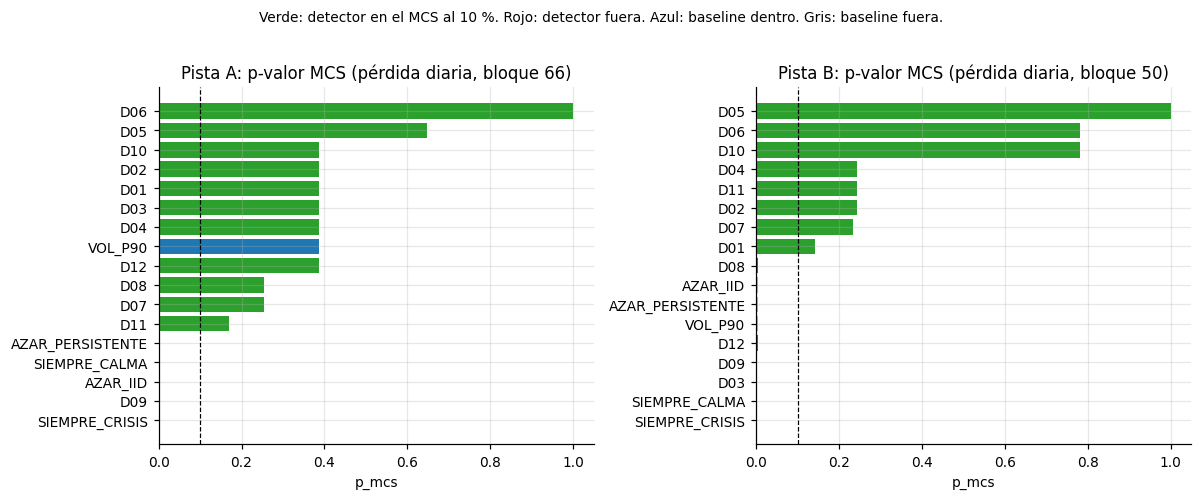

In [5]:
MCS_DIA = {}
for p in PISTAS:
    _, MCS_DIA[p] = mcs.mcs_senales(TODAS[p], WIN[p], lam=1.0, alpha=ALPHA, estadistico='T_max',
                                    block_len=BLOQUE[p], metodo='estacionario', n_boot=N_BOOT, seed=SEED,
                                    remuestreo='razon')
tabla_mcs = pd.concat([MCS_DIA[p].tabla.assign(pista=p, bloque=BLOQUE[p]) for p in PISTAS]).reset_index()
tabla_mcs.to_csv(VARA_DIR / 'mcs_diario.csv', index=False)
display(pd.concat({f'Pista {p}': MCS_DIA[p].tabla[['perdida_media', 'p_mcs', 'orden_eliminacion', 'incluido']]
                   for p in PISTAS}, axis=1).round(3))
for p in PISTAS:
    r = MCS_DIA[p]
    print(f'Pista {p}: MCS al 10 % = {r.supervivientes} ({len(r.supervivientes)} de {r.tabla.shape[0]}); '
          f'baselines dentro: {[b for b in BASELINES if b in r.supervivientes]}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, p in zip(axes, PISTAS):
    t = MCS_DIA[p].tabla.sort_values('p_mcs')
    colores = [('C0' if inc else '0.7') if m in BASELINES else ('C2' if inc else 'C3')
               for m, inc in zip(t.index, t['incluido'])]
    ax.barh(t.index, t['p_mcs'], color=colores)
    ax.axvline(ALPHA, color='k', ls='--', lw=.8)
    ax.set_title(f'Pista {p}: p-valor MCS (pérdida diaria, bloque {BLOQUE[p]})'); ax.set_xlabel('p_mcs')
fig.suptitle('Verde: detector en el MCS al 10 %. Rojo: detector fuera. Azul: baseline dentro. Gris: baseline fuera.',
             y=1.02, fontsize=9)
plt.tight_layout(); plt.show()

### 10.4 Sensibilidad: bloque, estadístico y MCS por crisis (el preliminar)

Mismas pérdidas diarias con otro bloque, con `T_R` o con el remuestreo «lineal» de pesos fijos (§10.2), y
la versión preliminar, que remuestrea **crisis**
(bootstrap iid sobre 17 / 9 crisis, término de falsa alarma constante por detector) con la pérdida media
idéntica. La preliminar se rehace aquí con el índice OOS exacto y `VOL_P90` con los datos verificados;
sus `AZAR_*` son la media de 200 simulaciones (como en `perdidas_por_crisis`), no una realización.

In [6]:
from arch.bootstrap import optimal_block_length

def _pw(L):
    # Politis y White (2004), bloque estacionario, mediana sobre los modelos no constantes.
    return int(round(optimal_block_length(L.loc[:, L.std() > 0])['stationary'].median()))

SENS = []
for p in PISTAS:
    variantes = {
        f'bloque {BLOQUE[p]} · T_max (principal)': dict(block_len=BLOQUE[p]),
        f'bloque {BLOQUE[p] // 2} (mitad)': dict(block_len=BLOQUE[p] // 2),
        f'bloque {2 * BLOQUE[p]} (doble)': dict(block_len=2 * BLOQUE[p]),
        f'bloque {_pw(PERD[p])} (Politis-White)': dict(block_len=_pw(PERD[p])),
        'bloque 1 (iid, ignora dependencia)': dict(block_len=1),
        f'bloque {BLOQUE[p]} · T_R': dict(block_len=BLOQUE[p], estadistico='T_R'),
    }
    variantes[f'bloque {BLOQUE[p]} · lineal (pesos fijos)'] = dict(block_len=BLOQUE[p], remuestreo='lineal')
    for nombre, kw in variantes.items():
        _, r = mcs.mcs_senales(TODAS[p], WIN[p], alpha=ALPHA, n_boot=N_BOOT, seed=SEED, **kw)
        SENS.append(r.tabla['p_mcs'].rename((p, nombre)))
    L_cr = mcs.perdidas_por_crisis(p, lam=1.0, metrics=METRICS[METRICS['pista'] == p],
                                   incluir_baselines=True, vol=VOL[p], oos_index=OOS[p], benchmark=BENCH)
    r = mcs.model_confidence_set(L_cr, alpha=ALPHA, n_boot=N_BOOT, seed=SEED)
    SENS.append(r.tabla['p_mcs'].rename((p, f'por crisis (preliminar, n = {r.n_obs})')))
sens = pd.concat(SENS, axis=1)
sens.columns = pd.MultiIndex.from_tuples(sens.columns, names=['pista', 'variante'])
sens = sens.reindex(MCS_DIA['A'].tabla.index)
sens.round(3).to_csv(VARA_DIR / 'mcs_sensibilidad.csv')
for p in PISTAS:
    print(f'Pista {p}: p_mcs (en el MCS al 10 % si ≥ 0,10)')
    display(sens[p].round(3))
    print('Tamaño del MCS:', (sens[p] >= ALPHA).sum().to_dict())

Pista A: p_mcs (en el MCS al 10 % si ≥ 0,10)


variante,bloque 66 · T_max (principal),bloque 33 (mitad),bloque 132 (doble),bloque 140 (Politis-White),"bloque 1 (iid, ignora dependencia)",bloque 66 · T_R,bloque 66 · lineal (pesos fijos),"por crisis (preliminar, n = 17)"
modelo,,,,,,,,
D06,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
D05,0.648,0.620,0.661,0.665,0.269,0.648,0.709,0.673
D01,0.386,0.273,0.433,0.426,0.001,0.232,0.709,0.552
D10,0.386,0.273,0.433,0.426,0.000,0.136,0.709,0.552
D12,0.386,0.273,0.433,0.426,0.000,0.110,0.709,0.552
VOL_P90,0.386,0.273,0.433,0.426,0.000,0.110,0.709,0.552
D03,0.386,0.273,0.433,0.426,0.000,0.099,0.709,0.552
D04,0.386,0.273,0.433,0.426,0.000,0.029,0.709,0.552
D02,0.386,0.273,0.433,0.426,0.000,0.099,0.709,0.552


Tamaño del MCS: {'bloque 66 · T_max (principal)': 12, 'bloque 33 (mitad)': 10, 'bloque 132 (doble)': 12, 'bloque 140 (Politis-White)': 12, 'bloque 1 (iid, ignora dependencia)': 2, 'bloque 66 · T_R': 6, 'bloque 66 · lineal (pesos fijos)': 12, 'por crisis (preliminar, n = 17)': 12}
Pista B: p_mcs (en el MCS al 10 % si ≥ 0,10)


variante,bloque 50 · T_max (principal),bloque 25 (mitad),bloque 100 (doble),bloque 80 (Politis-White),"bloque 1 (iid, ignora dependencia)",bloque 50 · T_R,bloque 50 · lineal (pesos fijos),"por crisis (preliminar, n = 9)"
modelo,,,,,,,,
D06,0.782,0.750,0.800,0.799,0.626,0.795,0.859,0.880
D05,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
D01,0.141,0.060,0.199,0.181,0.000,0.014,0.502,0.332
D10,0.782,0.750,0.800,0.799,0.198,0.795,0.859,0.880
D12,0.004,0.001,0.007,0.004,0.000,0.013,0.419,0.004
VOL_P90,0.004,0.001,0.007,0.004,0.000,0.013,0.502,0.004
D03,0.000,0.000,0.000,0.000,0.000,0.013,0.203,0.000
D04,0.244,0.166,0.314,0.310,0.000,0.249,0.530,0.654
D02,0.244,0.166,0.314,0.310,0.000,0.204,0.530,0.654


Tamaño del MCS: {'bloque 50 · T_max (principal)': 8, 'bloque 25 (mitad)': 7, 'bloque 100 (doble)': 8, 'bloque 80 (Politis-White)': 8, 'bloque 1 (iid, ignora dependencia)': 3, 'bloque 50 · T_R': 7, 'bloque 50 · lineal (pesos fijos)': 17, 'por crisis (preliminar, n = 9)': 8}


### 10.5 Validación contra `arch.bootstrap.MCS`

`arch` solo admite el MCS sobre medias de una matriz de pérdidas, así que se valida el **motor** del MCS con
el remuestreo lineal (misma matriz `PERD`, mismo bloque, bootstrap estacionario); las réplicas de razón usan
ese mismo motor con otras réplicas. Con las **mismas** réplicas que genera `arch` (sus índices bootstrap), los
p-valores coinciden exactamente con `T_max` y con `T_R` (`tests/evaluacion/test_mcs_diario.py`); aquí cada uno
genera las suyas, así que solo cabe esperar el error Monte Carlo. `method='max'` es
nuestro `T_max` y `method='R'` nuestro `T_R`. Las diferencias deben ser del orden del error Monte Carlo (comprobado el
2026-11-02 repitiendo el MCS lineal con 1.000 réplicas y tres semillas: diferencias de hasta 0,05 en A y 0,065
en B entre semillas de nuestra implementación y de 0,02–0,05 entre dos semillas de `arch`; el p-valor MCS es un
máximo acumulado y amplifica el ruido). En
la pista A se usan 1.000 réplicas en `arch` para no pasar de ~120 MB de índices.

In [7]:
from arch.bootstrap import MCS as ArchMCS

VALID = []
for p in PISTAS:
    reps = 2000 if p == 'B' else 1000
    for metodo, est in (('max', 'T_max'), ('R', 'T_R')):
        a = ArchMCS(PERD[p], size=ALPHA, reps=reps, block_size=BLOQUE[p], method=metodo,
                    bootstrap='stationary', seed=SEED)
        a.compute()
        nuestro = mcs.model_confidence_set(PERD[p], alpha=ALPHA, estadistico=est, block_len=BLOQUE[p],
                                           n_boot=N_BOOT, seed=SEED).tabla['p_mcs']
        cmp = pd.DataFrame({'arch': a.pvalues['Pvalue'], 'nuestro': nuestro})
        VALID.append({'pista': p, 'estadistico': est, 'reps_arch': reps,
                      'max_dif_p': float((cmp['arch'] - cmp['nuestro']).abs().max()),
                      'mismo_mcs': set(cmp.index[cmp['arch'] >= ALPHA]) == set(cmp.index[cmp['nuestro'] >= ALPHA])})
valid = pd.DataFrame(VALID)
valid.to_csv(VARA_DIR / 'mcs_validacion_arch.csv', index=False)
display(valid.round(3))

,pista,estadistico,reps_arch,max_dif_p,mismo_mcs
0,A,T_max,1000,0.072,True
1,A,T_R,1000,0.055,True
2,B,T_max,2000,0.019,False
3,B,T_R,2000,0.020,True


## 11. Curva a igual tasa de falsas alarmas (A3)

Para comparar detectores con distinto «gatillo», se calibra el umbral de cada uno para que dé la misma
tasa de falsas alarmas al año (0,5, 1 y 2) y se mira qué detecta y con cuánto retraso. Falsa alarma =
episodio (≥ 3 sesiones con señal) que **empieza** fuera de las ventanas de crisis; FA/año = falsas alarmas
/ años de calma. Retraso = sesiones desde el pico hasta la primera racha sostenida dentro de la ventana.
Ratio ruido-señal (KLR) = fracción de días de calma con señal / fracción de días de crisis con señal
(1 = azar).

Dos modos: `ex_post` (umbral único elegido con toda la muestra OOS; dispositivo descriptivo tipo ROC, **no
operativo**, y el principal para comparar a igual FA) y `expansivo` (umbral recalibrado cada año solo con
el pasado y las crisis ya terminadas; 3 años de burn-in, así que evalúa menos crisis).

### 11.1 Comprobación con una señal de juguete

Ocho crisis plantadas; la señal sube 5 sesiones después de cada pico. El retraso mediano debe ser 5.

In [8]:
rng = np.random.default_rng(1)
idx = pd.bdate_range('2000-01-03', periods=252 * 20)
score = pd.Series(rng.normal(size=len(idx)), index=idx)
ventanas = {}
for k, ini in enumerate(np.linspace(600, len(idx) - 300, 8).astype(int)):
    ventanas[f'crisis_{k}'] = (str(idx[ini].date()), str(idx[ini + 80].date()))
    score.iloc[ini + 5: ini + 80] += 4
display(curvas.curva_deteccion(score, ventanas, modo='ex_post').round(3))

,modo,fa_objetivo,umbral,dias_burn_in,fa_anio,n_falsas_alarmas,anios_calma,n_eventos,n_detectadas,tasa_deteccion,retraso_mediano,leadlag_suelo_mediano,tpr_dias,fpr_dias,ratio_ruido_senal
0,ex_post,0.5,1.132,0,0.402,7,17.429,8,8,1.0,5.0,-75.0,0.941,0.126,0.134
1,ex_post,1.0,0.922,0,0.918,16,17.429,8,8,1.0,5.0,-75.0,0.941,0.173,0.183
2,ex_post,2.0,0.804,0,1.893,33,17.429,8,8,1.0,5.0,-75.0,0.943,0.207,0.220


### 11.2 Curvas de los 12 detectores con los paneles

**Puntuación de cada panel.** Todos guardan `p_crisis` = probabilidad OOS del estado de crisis
(`proba[:, crisis_state]`). Para D01, D02 y D09 es **binaria** (0/1, idéntica a su estado): `curvas.py`
quita el umbral «marcar todos los días» y les deja solo dos puntos de operación, su propia señal o no
marcar nunca; si su señal da más falsas alarmas al año que el objetivo, a ese objetivo no detectan nada
(no es un fallo del cálculo: la regla no tiene más puntos). Los otros nueve tienen una probabilidad
continua (con muchos valores casi 0 o casi 1 en los HMM). Como referencia se añade **`VOL`**, la propia
`SP500_vol_z` como puntuación continua (la que hay detrás de `VOL_P90` y de D01 en A). Además se da el
**punto nativo** de cada uno (su `state`, sin recalibrar): FA/año, detección y retraso.

In [9]:
CURVAS = []
for p in PISTAS:
    scores = {d: pan['p_crisis'] for d, pan in PANELES[p].items()}
    scores['VOL'] = VOL[p]
    nativas = dict(SENALES[p])
    nativas['VOL'] = rk.vol_percentile_flags(VOL[p], OOS[p])   # punto nativo de VOL = VOL_P90
    c = curvas.curvas_detectores(scores, WIN[p], oos_index=OOS[p], senales_nativas=nativas, fp_windows=FP)
    CURVAS.append(c.assign(pista=p))
curva = pd.concat(CURVAS, ignore_index=True)
cols = ['pista', 'id', 'binaria', 'modo', 'fa_objetivo', 'umbral', 'fa_anio', 'n_detectadas', 'n_eventos',
        'tasa_deteccion', 'retraso_mediano', 'ratio_ruido_senal', 'n_fa_trampas',
        'fa_anio_nativa', 'deteccion_nativa', 'retraso_nativo']
curva[cols].to_csv(VARA_DIR / 'curvas.csv', index=False)

tipo = pd.DataFrame({p: {d: ('binaria' if curvas.es_binaria(pan['p_crisis']) else 'continua')
                         for d, pan in PANELES[p].items()} for p in PISTAS})
print('Tipo de puntuación (p_crisis) por panel:'); display(tipo.T)

# Punto principal: 1 falsa alarma al año, ex post.
uno = curva[(curva['fa_objetivo'] == 1.0) & (curva['modo'] == 'ex_post')]
for p in PISTAS:
    t = (uno[uno['pista'] == p]
         .sort_values(['tasa_deteccion', 'retraso_mediano', 'ratio_ruido_senal'], ascending=[False, True, True])
         [['id', 'binaria', 'fa_anio', 'n_detectadas', 'n_eventos', 'tasa_deteccion', 'retraso_mediano',
           'ratio_ruido_senal', 'n_fa_trampas', 'fa_anio_nativa', 'deteccion_nativa', 'retraso_nativo']])
    print(f'Pista {p}: 1 falsa alarma al año (ex post)')
    display(t.set_index('id').round(3))

Tipo de puntuación (p_crisis) por panel:


,D01,D02,D03,D04,D05,D06,D07,D08,D09,D10,D11,D12
A,binaria,binaria,continua,continua,continua,continua,continua,continua,binaria,continua,continua,continua
B,binaria,binaria,continua,continua,continua,continua,continua,continua,binaria,continua,continua,continua


Pista A: 1 falsa alarma al año (ex post)


,binaria,fa_anio,n_detectadas,n_eventos,tasa_deteccion,retraso_mediano,ratio_ruido_senal,n_fa_trampas,fa_anio_nativa,deteccion_nativa,retraso_nativo
id,,,,,,,,,,,
D06,False,0.995,16,17,0.941,19.0,0.206,0,1.593,1.000,8.0
D01,True,0.619,16,17,0.941,22.0,0.323,0,0.619,0.941,22.0
D05,False,0.841,14,17,0.824,30.0,0.234,0,4.911,1.000,5.0
D03,False,0.951,14,17,0.824,30.5,0.313,0,1.416,0.882,28.0
VOL,False,0.995,13,17,0.765,25.0,0.268,0,1.327,0.882,25.0
D04,False,0.995,12,17,0.706,20.0,0.685,0,1.305,1.000,6.0
D02,True,0.044,12,17,0.706,29.5,0.280,0,0.044,0.706,29.5
D07,False,0.973,12,17,0.706,31.0,0.248,0,0.177,0.824,4.0
D10,False,0.995,11,17,0.647,31.0,0.265,0,4.004,0.941,9.0


Pista B: 1 falsa alarma al año (ex post)


,binaria,fa_anio,n_detectadas,n_eventos,tasa_deteccion,retraso_mediano,ratio_ruido_senal,n_fa_trampas,fa_anio_nativa,deteccion_nativa,retraso_nativo
id,,,,,,,,,,,
D06,False,0.976,8,9,0.889,14.5,0.166,0,1.126,0.889,12.5
VOL,False,0.976,8,9,0.889,22.0,0.244,0,0.225,0.556,72.0
D07,False,0.825,8,9,0.889,24.0,0.250,0,0.150,0.556,68.0
D04,False,0.901,7,9,0.778,31.0,0.387,0,0.600,0.778,31.0
D10,False,0.976,6,9,0.667,19.0,0.250,0,6.154,1.000,3.0
D01,True,0.300,6,9,0.667,23.0,0.305,0,0.300,0.667,23.0
D02,True,0.075,6,9,0.667,37.5,0.311,0,0.075,0.667,37.5
D05,False,0.825,5,9,0.556,35.0,0.196,0,2.326,1.000,12.0
D12,False,0.825,4,9,0.444,31.0,0.392,1,0.450,0.222,49.0


Pista A: detección y retraso mediano (sesiones) por objetivo de FA/año


det                                       retraso_mediano  \
modo        ex_post               expansivo                       ex_post   
fa_objetivo     0.5    1.0    2.0       0.5    1.0    2.0             0.5   
id                                                                          
D01            0/17  16/17  16/17      0/16  14/16  15/16             NaN   
D02           12/17  12/17  12/17     11/16  11/16  11/16            29.5   
D03            0/17  14/17  16/17      0/16   7/16  14/16             NaN   
D04            0/17  12/17  17/17      0/16   3/16  15/16             NaN   
D05           11/17  14/17  14/17     10/16  13/16  13/16            34.0   
D06           13/17  16/17  16/17     12/16  15/16  15/16            32.0   
D07            8/17  12/17  16/17      7/16   9/16  15/16            43.5   
D08            7/17  11/17  16/17      3/16   7/16  16/16            41.0   
D09            8/17   8/17   8/17      7/16   7/16   7/16            31.0   
D10            9/17  11/17  16/17      6/16   8/16  14/16            35.0   
D11            6/17   8/17  15/17      1/16   7/16  13/16            19.5   
D12            0/17   7/17  13/17      0/16   3/16   6/16             NaN   
VOL           13/17  13/17  17/17     13/16  15/16  16/16            30.0   

                                               
modo                    expansivo              
fa_objetivo   1.0   2.0       0.5   1.0   2.0  
id                                             
D01          22.0  22.0       NaN  22.0  19.0  
D02          29.5  29.5      27.0  27.0  27.0  
D03          30.5  18.5       NaN  69.0  22.0  
D04          20.0   3.0       NaN  31.0   6.0  
D05          30.0  22.0      29.0  29.0  26.0  
D06          19.0  10.0      30.5  16.0  12.0  
D07          31.0  13.0      38.0  29.0  11.0  
D08          41.0   7.5      35.0  69.0  12.5  
D09          31.0  31.0      41.0  41.0  41.0  
D10          31.0  24.0      33.0  33.0  24.0  
D11          19.5   0.0      25.0  15.0   2.0  
D12          69.0  35.0       NaN  69.0  89.0  
VOL          25.0  10.0      31.0  19.0   8.5

Pista B: detección y retraso mediano (sesiones) por objetivo de FA/año


det                               retraso_mediano              \
modo        ex_post           expansivo                   ex_post               
fa_objetivo     0.5  1.0  2.0       0.5  1.0  2.0             0.5   1.0   2.0   
id                                                                              
D01             6/9  6/9  6/9       5/7  5/7  5/7            23.0  23.0  23.0   
D02             6/9  6/9  6/9       5/7  5/7  5/7            37.5  37.5  37.5   
D03             3/9  4/9  4/9       4/7  4/7  4/7            49.0  38.0  17.0   
D04             0/9  7/9  8/9       5/7  7/7  7/7             NaN  31.0  27.5   
D05             4/9  5/9  7/9       4/7  5/7  5/7            46.5  35.0  16.0   
D06             7/9  8/9  8/9       6/7  6/7  7/7            32.0  14.5  10.5   
D07             3/9  8/9  8/9       3/7  6/7  6/7            28.0  24.0  15.0   
D08             3/9  3/9  4/9       1/7  2/7  4/7            13.0  13.0  11.5   
D09             0/9  0/9  0/9       0/7  0/7  0/7             NaN   NaN   NaN   
D10             3/9  6/9  8/9       6/7  6/7  6/7            10.0  19.0  11.5   
D11             3/9  3/9  3/9       3/7  3/7  3/7             8.0   6.0   3.0   
D12             2/9  4/9  4/9       3/7  3/7  4/7            62.0  31.0  30.0   
VOL             6/9  8/9  9/9       5/7  6/7  7/7            50.5  22.0   6.0   

                                   
modo        expansivo              
fa_objetivo       0.5   1.0   2.0  
id                                 
D01              15.0  15.0  15.0  
D02              32.0  32.0  32.0  
D03              40.0  20.5  15.5  
D04               6.0  24.0  13.0  
D05              39.0  14.0  14.0  
D06              23.5  14.5   7.0  
D07              34.0  17.5   5.5  
D08              41.0   6.5   2.0  
D09               NaN   NaN   NaN  
D10              19.0   8.0   1.0  
D11               8.0   8.0   6.0  
D12             113.0  38.0  32.0  
VOL              32.0  20.5   6.0

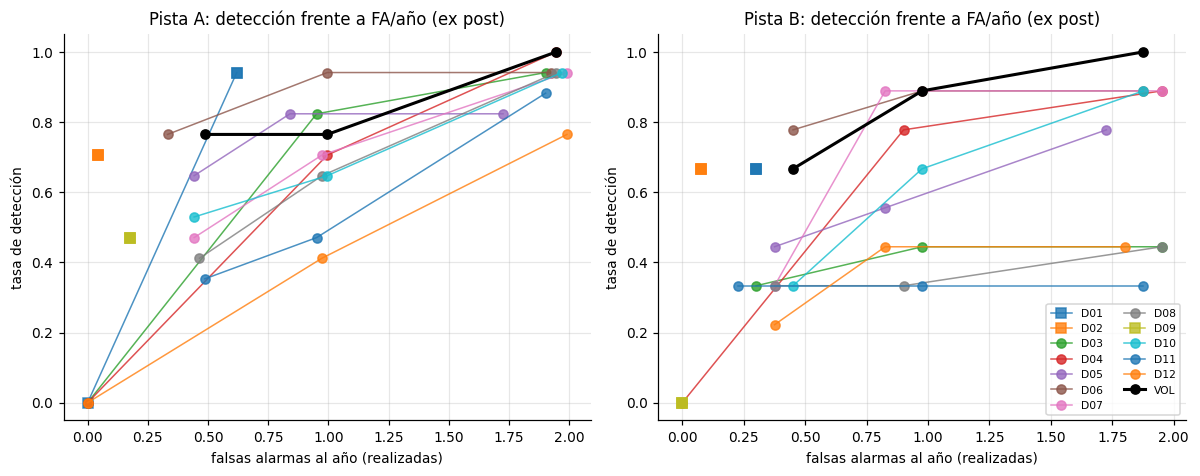

In [10]:
# Las tres tasas y los dos modos, compactos: detección (n detectadas / n eventos) y retraso mediano.
curva['det'] = curva['n_detectadas'].astype(int).astype(str) + '/' + curva['n_eventos'].astype(int).astype(str)
for p in PISTAS:
    t = curva[curva['pista'] == p].pivot_table(index='id', columns=['modo', 'fa_objetivo'],
                                               values=['det', 'retraso_mediano'], aggfunc='first')
    print(f'Pista {p}: detección y retraso mediano (sesiones) por objetivo de FA/año')
    display(t.reindex(columns=['det', 'retraso_mediano'], level=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, p in zip(axes, PISTAS):
    t = curva[(curva['pista'] == p) & (curva['modo'] == 'ex_post')]
    for d, g in t.groupby('id'):
        estilo = dict(color='k', lw=2) if d == 'VOL' else dict(lw=1, alpha=.8)
        ax.plot(g['fa_anio'], g['tasa_deteccion'], marker='o' if not g['binaria'].iloc[0] else 's',
                label=d, **estilo)
    ax.set_xlabel('falsas alarmas al año (realizadas)'); ax.set_ylabel('tasa de detección')
    ax.set_title(f'Pista {p}: detección frente a FA/año (ex post)')
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

### 11.3 `VOL_P90` frente a los detectores

En el ranking por `score_deteccion` (§9.1), en el MCS (§10.3) y en la curva (§11.2, `VOL`).

In [11]:
filas = []
for p in PISTAS:
    t = MCS_DIA[p].tabla
    r = ranking[ranking['pista'] == p]
    v = baselines.query('pista == @p and id == "VOL_P90"').iloc[0]
    u = uno[(uno['pista'] == p) & (uno['id'] == 'VOL')].iloc[0]
    filas.append({
        'pista': p,
        'score_VOL_P90': v['score_deteccion'],
        'detectores_con_mas_score': int((r['score_deteccion'] > v['score_deteccion']).sum()),
        'perdida_VOL_P90': t.loc['VOL_P90', 'perdida_media'],
        'detectores_con_menos_perdida': int((t.drop(BASELINES)['perdida_media'] < t.loc['VOL_P90', 'perdida_media']).sum()),
        'p_mcs_VOL_P90': t.loc['VOL_P90', 'p_mcs'],
        'det_VOL_1FA': f"{int(u['n_detectadas'])}/{int(u['n_eventos'])}",
        'retraso_VOL_1FA': u['retraso_mediano'],
        'detectores_con_mas_deteccion_1FA': int((uno[(uno['pista'] == p) & (uno['id'] != 'VOL')]['n_detectadas']
                                                 > u['n_detectadas']).sum()),
    })
vol_vs = pd.DataFrame(filas).set_index('pista')
vol_vs.to_csv(VARA_DIR / 'vol_p90_frente_detectores.csv')
display(vol_vs.round(3).T)

pista,A,B
score_VOL_P90,0.6,0.525
detectores_con_mas_score,1,2
perdida_VOL_P90,0.662,0.896
detectores_con_menos_perdida,5,9
p_mcs_VOL_P90,0.386,0.004
det_VOL_1FA,13/17,8/9
retraso_VOL_1FA,25.0,22.0
detectores_con_mas_deteccion_1FA,4,0


## 12. Tabla CP1 y cierre

### 12.0 Tabla CP1: MCS de los 12 por pista

Por pista: detectores en el MCS al 10 % con su p-valor, detectores fuera y baselines triviales que entran.
Debajo, la pregunta de A1 («¿D10 y D01 se distinguen?»): intervalo bootstrap al 90 % (mismo bloque) de la
diferencia de pérdida media D10 − D01.

In [12]:
CP1 = []
for p in PISTAS:
    t = MCS_DIA[p].tabla
    for m in t.index:
        CP1.append({'pista': p, 'id': m, 'tipo': 'baseline' if m in BASELINES else 'detector',
                    'perdida_media': t.loc[m, 'perdida_media'], 'p_mcs': t.loc[m, 'p_mcs'],
                    'en_mcs': bool(t.loc[m, 'incluido'])})
cp1 = pd.DataFrame(CP1)
cp1.to_csv(VARA_DIR / 'cp1_mcs.csv', index=False)

resumen = []
for p in PISTAS:
    g = cp1[cp1['pista'] == p]
    det, base = g[g['tipo'] == 'detector'], g[g['tipo'] == 'baseline']
    resumen.append({
        'pista': p, 'bloque': BLOQUE[p],
        'en_MCS (p_mcs)': ', '.join(f'{r.id} ({r.p_mcs:.2f})' for r in det[det['en_mcs']].itertuples()),
        'fuera (p_mcs)': ', '.join(f'{r.id} ({r.p_mcs:.3f})' for r in det[~det['en_mcs']].itertuples()),
        'baselines dentro (p_mcs)': ', '.join(f'{r.id} ({r.p_mcs:.2f})' for r in base[base['en_mcs']].itertuples()) or '—',
    })
cp1_resumen = pd.DataFrame(resumen).set_index('pista')
cp1_resumen.to_csv(VARA_DIR / 'cp1_resumen.csv')
with pd.option_context('display.max_colwidth', 400):
    display(cp1_resumen.T)

for p in PISTAS:
    b = mcs.replicas_perdida(TODAS[p][['D10', 'D01']], WIN[p], n_boot=N_BOOT, block_len=BLOQUE[p], seed=SEED)
    d = b[:, 0] - b[:, 1]
    obs = PERD[p]['D10'].mean() - PERD[p]['D01'].mean()
    lo, hi = np.quantile(d - obs, [0.95, 0.05])   # IC básico al 90 %
    print(f'Pista {p}: pérdida D10 − D01 = {obs:+.3f}, IC 90 % [{obs - lo:+.3f}, {obs - hi:+.3f}]')

pista,A,B
bloque,66,50
en_MCS (p_mcs),"D06 (1.00), D05 (0.65), D01 (0.39), D10 (0.39), D12 (0.39), D03 (0.39), D04 (0.39), D02 (0.39), D08 (0.25), D07 (0.25), D11 (0.17)","D05 (1.00), D06 (0.78), D10 (0.78), D04 (0.24), D11 (0.24), D02 (0.24), D07 (0.23), D01 (0.14)"
fuera (p_mcs),D09 (0.000),"D12 (0.004), D08 (0.004), D03 (0.000), D09 (0.000)"
baselines dentro (p_mcs),VOL_P90 (0.39),—


Pista A: pérdida D10 − D01 = +0.044, IC 90 % [-0.043, +0.113]


Pista B: pérdida D10 − D01 = -0.175, IC 90 % [-0.335, -0.070]


### 12.1 Lectura (versión definitiva, paneles v2)

Todas las cifras salen de las celdas de §9–§12.0 y de los CSV de `results/benchmark/vara/`.

- **Pérdida y bloque.** Pérdida diaria con media (1/K)·Σ(1 − cobertura) + FPR (λ = 1, crisis
  equiponderadas); réplicas de razón con bootstrap estacionario de bloque medio 66 sesiones en A y 50 en B
  (mediana de las ventanas OOS). La señal reconstruida desde los paneles reproduce la cobertura de los CSV
  (diferencia máxima 1e-16).
- **MCS al 10 %, pista A:** 11 de los 12 detectores (D06 1,00; D05 0,65; D01, D10, D12, D03, D04 y D02
  0,39; D08 y D07 0,25; D11 0,17) **y `VOL_P90` (0,39)**. Fuera: D09 (0,000) y los cuatro baselines sin
  información (`SIEMPRE_*`, `AZAR_*`, p ≤ 0,001).
- **MCS al 10 %, pista B:** 8 de los 12 (D05 1,00; D06 y D10 0,78; D04, D11 y D02 0,24; D07 0,23; D01 0,14).
  Fuera: D12, D08 (0,004), D03 y D09 (0,000), **`VOL_P90` (0,004)** y todos los baselines sin información.
  Ningún baseline trivial entra en B; en A solo entra `VOL_P90`.
- **¿D10 y D01 se distinguen?** En el MCS, no: están juntos en las dos pistas. Por pares (IC 90 % de la
  pérdida D10 − D01): en A +0,044 [−0,043, +0,113], indistinguibles; en B −0,175 [−0,335, −0,070], D10 mejor
  que D01. Ojo: el orden por pérdida no es el de `score_deteccion` (en A, D01 pierde menos que D10; los
  mejores por pérdida son D06 en A y D05 en B, que penaliza menos su precisión baja).
- **Sensibilidad.** El bloque doble o el de Politis-White (140 en A, 80 en B) dejan el MCS igual (12 y 8);
  la mitad lo encoge a 10 y 7 (salen D07 y D11 en A, D01 en B); `T_R` es más estricto (6 en A, 7 en B).
  Bloque 1 (iid, ignora la dependencia) deja 2–3 modelos y no es creíble. El remuestreo lineal de pesos fijos
  mete en B los 17 modelos, `SIEMPRE_CRISIS` incluido: es el artefacto descrito en §10.2.
- **Frente al preliminar (por crisis).** **Mismos miembros** en las dos pistas (12 en A, 8 en B, con los
  mismos fuera), pero p-valores más bajos: en A el grupo de D01 pasa de 0,55 a 0,39 y D11 de 0,55 a 0,17; en
  B D01 de 0,33 a 0,14 y D04/D02/D11 de 0,65 a 0,24. Al remuestrear días entra la incertidumbre de las falsas
  alarmas, que en la versión por crisis era constante. La pérdida media por detector es la misma por
  construcción.
- **Validación.** El motor del MCS reproduce `arch.bootstrap.MCS` con diferencias de p-valor de 0,02 (B) a
  0,07 (A, 1.000 réplicas en `arch`), del orden del error Monte Carlo; el conjunto coincide salvo en B con
  `T_max`, donde `AZAR_IID` está justo en la frontera (0,100 frente a 0,088).
- **Curva a 1 falsa alarma al año (ex post).** A: D06 detecta 16/17 con 19 sesiones de retraso mediano y ratio
  ruido-señal 0,21; D01 16/17 con 22 (su única señal ya da 0,62 FA/año); D05 y D03 14/17 con 30 y 30,5; D10 11/17 con
  31. B: D06 8/9 con 14,5 y ratio 0,17; D07 8/9 con 24; D04 7/9 con 31; D10 y D01 6/9 con 19 y 23; D09 0/9.
  En modo expansivo (causal) el orden se mantiene en A (D06 15/16 con 16, D01 14/16 con 22), pero en B la
  tasa realizada se pasa del objetivo en 6 de 12 (D10 4,1 FA/año): calibrar con 3–5 años de pasado es frágil.
  Los binarios D01, D02 y D09 no tienen más puntos que su señal: a 0,5 FA/año D01 no detecta nada en A.
- **`VOL_P90` frente a los detectores.** Por `score_deteccion` solo le ganan D10 en A (0,600) y D05 y D06 en B
  (0,525). En pérdida MCS le ganan 5 detectores en A (está en el MCS) y 9 en B (fuera: casi nunca marca en B,
  FPR 0,026, y falla mucho). Como puntuación continua (`VOL`) a 1 FA/año detecta 13/17 en A (le superan D06,
  D01, D05 y D03) y 8/9 en B con 22 sesiones (nadie le supera; empata con D06 y D07). **La volatilidad sola
  sigue siendo un rival serio**; en B lo que falla es el percentil 90 como umbral, no la señal.

### 12.2 Cierre

Este notebook termina cuando existen 24 filas válidas —12 detectores por dos pistas—
o cuando cualquier excepción queda documentada como incompatibilidad explícita. No
se interpreta aquí el ganador: cada notebook de familia (06–12) analiza sus detectores y
`14_comparativa.ipynb` carga los artefactos, verifica comparabilidad dentro de cada pista
y construye la evidencia visual.

La prueba pseudolive estricta es la validación final de la señal de régimen de la Fase 1 (la que
alimentará a los agentes del TFM), no la meta del TFM. Será posterior a esta comparación y utilizará
un tramo final congelado que no intervenga en la selección.